# Function 2 - Week 5: exploration review

Review measured outputs and input coverage in the independent Week 5 `observations.csv`, including the confirmed Week 4 return received on **23 October 2026**.

The saved exploration shortlist is complete; a new Week 5 query requires a separate decision. Descriptive plots and the observed-output terrain follow the Week 4 pattern. Continue in [model predictions](model_predictions.ipynb) to compare methods and decide on one model-led Week 5 query. The [Week 4 model notebook](../Week_04/model_predictions.ipynb) remains a historical learning study.


In [2]:
# Imports & shared helpers
import numpy as np
import pandas as pd
from pathlib import Path
import sys

# Find Shared from any function/week folder inside notebooks.
shared_dir = next(
    (folder / "Shared"
     for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "Shared" / "plot_helpers.py").is_file()),
    None,
)
if shared_dir is None:
    raise FileNotFoundError(
        "Cannot find Shared/plot_helpers.py above the working directory. "
        "Run this notebook from within the notebooks folder."
    )
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))

from plot_helpers import (
    PLOT_CONFIG, plot_observed_terrain,
    plot_sampling_gaps, plot_fixed_exploration_progression,
    plot_output_number_line,
)
from output_helpers import summarise_output_observations


In [3]:
# Data and output paths for this week's notebook.
# Start the kernel with this notebook's folder as its working directory.
week_dir = Path.cwd().resolve()
full_data_path = week_dir / "observations.csv"

if not (week_dir / "exploration-review.ipynb").is_file() or not full_data_path.is_file():
    raise FileNotFoundError(
        "Run this notebook with its own folder as the working directory; "
        "exploration-review.ipynb and observations.csv must be together."
    )

figures = week_dir / "figures"
figures.mkdir(parents=True, exist_ok=True)



In [4]:
# Basic data load
print(f"Loading data from: {full_data_path}")
data = pd.read_csv(full_data_path, float_precision="round_trip")

Loading data from: C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\stage-2-bbo\notebooks\Function_2\Week_05\observations.csv


In [5]:
# Column inspection
columns = data.columns
print("Columns: ", columns)

Columns:  Index(['observation_id', 'source_round', 'x1', 'x2', 'y'], dtype='str')


In [6]:
# Where we pray for good data, aka checking for nulls
print (data.isna().sum())

observation_id    0
source_round      0
x1                0
x2                0
y                 0
dtype: int64


In [7]:
# Prepare observation labels for the exploration plots
plot_data = data.copy()
plot_data["rank"] = (
    plot_data["y"]
    .rank(ascending=False, method="min")
    .astype(int)
)

In [8]:
# Splitting our data into inputs X and outputs y
output_column = "y"
input_columns = ["x1", "x2"]

#print("Input columns: ", input_columns)
#print("Output column: ", output_column)

X = data[input_columns]
y = data[output_column]

#print("The inputs are given by :")
#print(X.head())
#print("The outputs are given by :")
#print(y[:5])


In [9]:
# So now we have:

# data	       = Observations as loaded from the CSV
# X, y	       = Inputs and outputs selected from those observations
# plot_data	   = A separate copy enriched for the exploration plots

In [10]:
# Review the latest recorded submission against earlier observed outputs.
output_review = summarise_output_observations(
    data,
    input_columns=input_columns,
    output_column=output_column,
)
print(output_review["report"])


Latest recorded submission: round 4 (1 new output).
Compared with 13 earlier observations (14 outputs in total).
Earlier output range: [-0.0656236244373, 0.611205215761].

round-04: y = 0.131194318634 (positive); rank 9/14 (1 = highest output).
Inputs: x1 = 0.17954, x2 = 0.808737
Within the earlier output range.


The Week 4 return is **0.131194318634**, ranked **9/14 (1 = highest output)**. It does not improve the incumbent of **0.611205215761** (initial-010).

## Observed outputs

A linear number line suits Function 2's moderate output range. The latest submission is starred;
zero is an ordinary point on this scale.


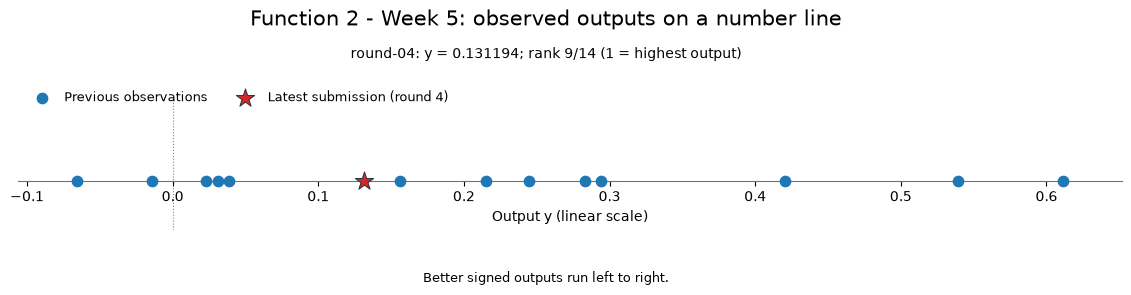

In [11]:
plot_output_number_line(
    output_review,
    title="Function 2 - Week 5: observed outputs on a number line",
    save_to=figures / "output-number-line.png",
)

## Observed ranks and sampling gaps

Numbers are observed output ranks (1 = highest). The background shows distance to the nearest observed point.


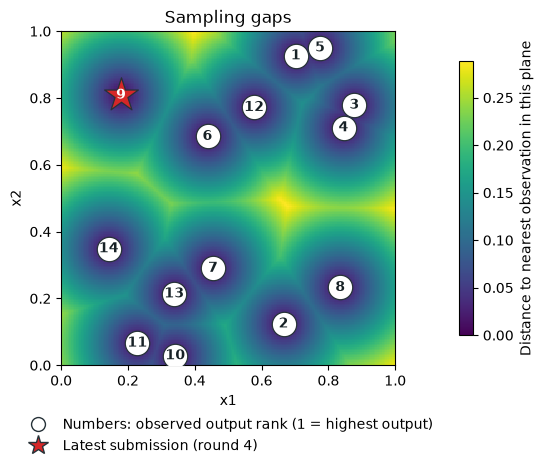

In [12]:
# Visualisation of the input-space coverage of the observations so far.
sampling_gaps_fig = plot_sampling_gaps(
    plot_data, highlight=output_review["latest_mask"],
    highlight_label=f"Latest submission (round {output_review['latest_round']})",
)
sampling_gaps_fig.set_size_inches(sampling_gaps_fig.get_size_inches() * 0.75)
sampling_gaps_fig.savefig(figures / "sampling-gaps.png", dpi=160)
sampling_gaps_fig


## Observed-output terrain

Use `x1` and `x2` as the ground plane and the measured output `y` as height.
Function 2's moderate output range suits a linear scale; the vertical aspect ratio of `0.16` flattens the relief.
Black markers are measurements; the gold diamond identifies the highest observed output.
The triangular faces simply join measured heights. They are a visual interpolation, not a fitted regression or a known function surface.
Blank areas lie outside the sampled region. Drag to rotate, scroll to zoom, and use **Reset view** to restore the initial orientation and zoom.


In [13]:
# Function 2 uses raw output heights, with the same shared terrain renderer.
terrain_y = y.to_numpy(dtype=float)
terrain_html = figures / "observed-output-terrain.html"
terrain_fig = plot_observed_terrain(
    X.to_numpy(), terrain_y,
    title=f"Function 2: observed-output terrain ({len(terrain_y)} samples)",
    relief=0.16, save_to=terrain_html,
    width=850, height=560, camera=dict(eye=dict(x=-1.05, y=-1.35, z=0.9)),
    show_reset=True,
)
print(f"Raw output heights: {terrain_y.min():.4f} to {terrain_y.max():.4f} ({len(terrain_y)} observations).")
print(f"Interactive browser copy: {terrain_html}")
terrain_fig.show(config={**PLOT_CONFIG, "responsive": False})


Raw output heights: -0.0656 to 0.6112 (14 observations).
Interactive browser copy: C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\stage-2-bbo\notebooks\Function_2\Week_05\figures\observed-output-terrain.html


## Completed exploration plan

In [14]:
# Fixed Week 2 plan, preserved at full precision; no optimisation is run.
planned_queries = pd.DataFrame(
    [[0.22823414192856306, 0.06664413600559765], [0.8355651699511926, 0.23291097243365763], [0.17953980688500848, 0.8087368655610445]],
    columns=input_columns,
)

# The saved sequence starts in Week 2; keep only this week's unevaluated remainder.
current_week = int(week_dir.name.removeprefix("Week_"))
coverage_queries = planned_queries.iloc[current_week - 2:].copy()


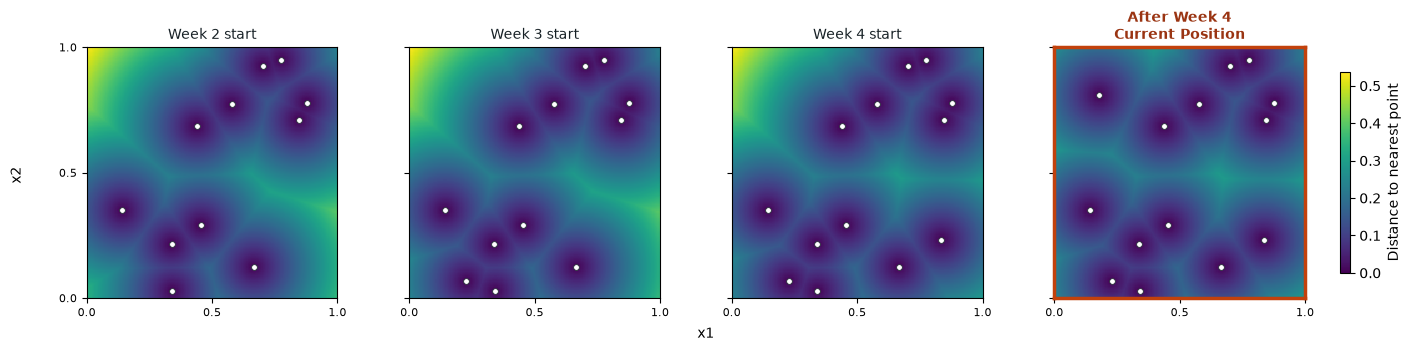

In [15]:
plot_fixed_exploration_progression(
    data, planned_queries,
    current_week=current_week,
    save_to=figures / "fixed-exploration-progression.png",
)

In [16]:
# Copy the portal-ready input from the row for the required week.
remaining_queries = coverage_queries.copy()
remaining_queries.index = pd.Index(
    range(current_week, current_week + len(remaining_queries)), name="Week",
)
remaining_queries["Portal input"] = [
    "-".join(f"{value:.6f}" for value in point)
    for point in coverage_queries.to_numpy()
]
if remaining_queries.empty:
    print("The saved Week 2 exploration plan is complete. No Week 5 input is selected here.")
else:
    display(remaining_queries.style.format({column: "{:.6f}" for column in input_columns}))

The saved Week 2 exploration plan is complete. No Week 5 input is selected here.


## Continue with model predictions

The saved exploration shortlist is complete. This notebook closes the fixed-plan observation review; completing the shortlist does not establish that exploration of the unknown function is complete.

Continue in [model predictions](model_predictions.ipynb) for fresh validation, fitted predictions, uncertainty and a proposed Week 5 input. Both notebooks load the same independent snapshot of **14 observations through round 4**. The model-led proposal remains unsubmitted.